In [11]:
import os
import pandas as pd
import sqlite3
import numpy as np

# Compacting the spatial current-density map

The CDDM records **667 local currents per row** (`Current_0…666`), arranged in a **29 × 23 matrix** (S++ board between cells 5 and 6; companion Fuel Cells paper). The flow direction is the **29-axis**; the outer ring are boundary segments the authors exclude with a correction factor (Eq. 1–2), leaving a **27 × 21 interior**.

Goal: replace the 667 columns with a few features that keep the aging- and operating-point-relevant structure. Two routes are compared here on steady-state maps:

1. **PCA / SVD** — data-driven modes (no assumption, but modes need interpreting).
2. **Physics features** — flow-direction gradient, heterogeneity (CoV), peak position, and lateral descriptors (interpretable, directly comparable to the paper).

All analysis is on each map **normalized by its own mean**, so it describes the *distribution* independent of load level (load is just `mean_j`, kept separately).

In [12]:
import os, sqlite3
import numpy as np
import pandas as pd
from contextlib import closing

HERE = os.getcwd()
PROJECT_DIR = os.path.dirname(HERE)
DB_path = os.path.join(PROJECT_DIR, "cathode_degradation.db")

NROW, NCOL = 29, 23                       # CDDM matrix; flow along axis 0 (29), lateral axis 1 (23)
SEG = [f"Current_{i}" for i in range(NROW * NCOL)]   # Current_0 .. Current_666

In [13]:
# --- grid helpers -------------------------------------------------------------
def reshape_map(flat):
    """667-vector -> 29x23 grid (flow along axis 0)."""
    return np.asarray(flat, float).reshape(NROW, NCOL)

def interior(grid):
    """drop the excluded boundary ring -> 27x21."""
    return grid[1:NROW-1, 1:NCOL-1]

def boundary_corrected(flat):
    """Paper Eq. 1-2: rescale the interior so it carries the full cell current.
    (For shape/normalised analysis this cancels, but kept for correctness.)"""
    g = reshape_map(flat)
    corr = interior(g).sum() / g.sum()
    return interior(g) / corr

In [14]:
# --- build steady-state maps: mean segment map per (age_h, load bin) ----------
def build_steady_maps(db_path=DB_path, jmin=0.25):
    sel = ",".join(f'"{c}"' for c in SEG)
    frames = []
    with closing(sqlite3.connect(f"file:{db_path}?mode=ro", uri=True)) as con:
        ages = [r[0] for r in con.execute(
            "SELECT DISTINCT age_h FROM polarization_raw WHERE air_air_start=0 ORDER BY age_h")]
        for age in ages:                 # one age at a time keeps memory bounded
            df = pd.read_sql_query(
                f'SELECT ROUND("j.S.act [A/cm2]",1) AS j_bin, {sel} FROM polarization_raw '
                f'WHERE age_h={age} AND air_air_start=0 AND "j.S.act [A/cm2]" > {jmin}', con)
            g = df.groupby("j_bin")[SEG].mean()
            g.index = pd.MultiIndex.from_product([[age], g.index], names=["age_h", "j_bin"])
            frames.append(g)
    return pd.concat(frames)

maps = build_steady_maps()
print("steady maps:", maps.shape, "| (age_h, j_bin) index")
maps.index.to_frame(index=False).head()

steady maps: (144, 667) | (age_h, j_bin) index


,age_h,j_bin
0,0,0.3
1,0,0.4
2,0,0.5
3,0,0.6
4,0,0.7


In [15]:
# interior, mean-normalised (distribution only)
I  = np.array([boundary_corrected(m).ravel() for m in maps.values])
In = I / I.mean(axis=1, keepdims=True)
print("interior maps:", In.shape, "(maps x 567 segments)")

interior maps: (144, 567) (maps x 567 segments)


## Route 1: physics features

In [16]:
def map_features(flat):
    g    = boundary_corrected(flat)
    flow = g.mean(axis=1)                 # 27-pt profile along flow
    lat  = g.mean(axis=0)                 # 21-pt profile across flow
    return pd.Series({
        "mean_j":            g.mean(),                                   # load level (kept separate)
        "heterogeneity_CoV": g.std() / g.mean(),                        # overall non-uniformity
        "flow_gradient":     np.polyfit(np.arange(len(flow)), flow/flow.mean(), 1)[0],
        "peak_pos":          int(np.argmax(flow)),                      # peak location along flow
        "lateral_gradient":  np.polyfit(np.arange(len(lat)),  lat/lat.mean(),  1)[0],
        "lateral_CoV":       lat.std() / lat.mean(),                    # cross-flow non-uniformity
    })

feat = maps.apply(lambda r: map_features(r.values), axis=1)
feat.describe().round(4)

,mean_j,heterogeneity_CoV,flow_gradient,peak_pos,lateral_gradient,lateral_CoV
count,144.0000,144.0000,144.0000,144.0000,144.0000,144.0000
mean,0.5188,0.1454,-0.0063,9.1528,0.0013,0.0589
std,0.2291,0.0100,0.0033,1.1485,0.0001,0.0051
min,0.1347,0.1193,-0.0114,8.0000,0.0009,0.0431
25%,0.3403,0.1385,-0.0086,8.0000,0.0012,0.0577
50%,0.5151,0.1483,-0.0065,10.0000,0.0013,0.0601
75%,0.7162,0.1532,-0.0053,10.0000,0.0014,0.0624
max,0.8885,0.1602,0.0047,16.0000,0.0018,0.0661


## Route 2: PCA on the normalised maps

In [17]:
from sklearn.decomposition import PCA

pca = PCA().fit(In)                       # sklearn centres automatically
evr = pca.explained_variance_ratio_
print("explained variance ratio:", np.round(evr[:6], 4))
print("cumulative              :", np.round(np.cumsum(evr[:6]), 4))

for k in (1, 2, 3, 5):
    pk  = PCA(k).fit(In)
    rec = pk.inverse_transform(pk.transform(In))
    resid = np.sqrt(((In - rec) ** 2).sum() / (In ** 2).sum()) * 100
    print(f"  k={k}: reconstruction residual {resid:5.2f}%")

explained variance ratio: [0.5945 0.3124 0.045  0.0306 0.0066 0.0038]
cumulative              : [0.5945 0.9069 0.9519 0.9826 0.9891 0.9929]
  k=1: reconstruction residual  2.19%
  k=2: reconstruction residual  1.05%
  k=3: reconstruction residual  0.75%
  k=5: reconstruction residual  0.36%


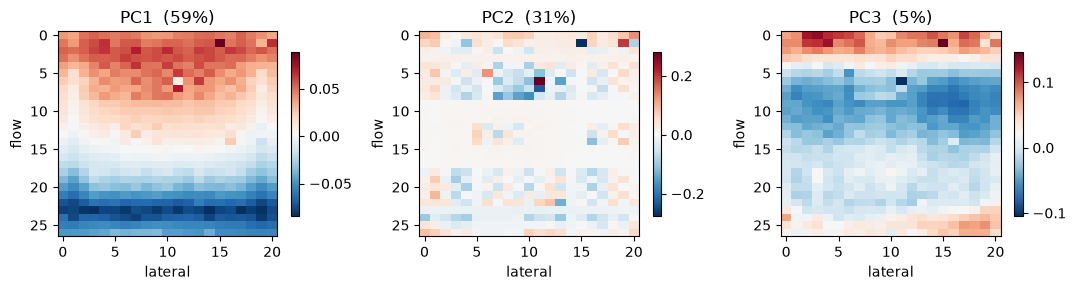

In [18]:
# visualise the first 3 modes on the 27x21 interior grid
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(11, 3))
for k in range(3):
    im = ax[k].imshow(pca.components_[k].reshape(27, 21), aspect="auto", cmap="RdBu_r")
    ax[k].set_title(f"PC{k+1}  ({evr[k]*100:.0f}%)"); ax[k].set_xlabel("lateral"); ax[k].set_ylabel("flow")
    fig.colorbar(im, ax=ax[k], shrink=0.8)
plt.tight_layout(); plt.show()

## Do the physics features span the PCA subspace?

In [19]:
scores = PCA(3).fit_transform(In)
corr = pd.DataFrame(
    {f"PC{p+1}": [abs(np.corrcoef(scores[:, p], feat[c])[0, 1]) for c in feat.columns[1:]]
     for p in range(3)},
    index=feat.columns[1:])
corr.round(2)

,PC1,PC2,PC3
heterogeneity_CoV,0.80,0.13,0.42
flow_gradient,1.00,0.09,0.02
peak_pos,0.28,0.38,0.13
lateral_gradient,0.44,0.10,0.25
lateral_CoV,0.61,0.76,0.01


## Findings & recommendation

On steady-state maps spanning load and age (mean-normalised, boundary-corrected):

- The distribution is **low-rank: 3 modes explain 95%** of the variance (PC1 = 59%, PC2 = 31%, PC3 = 5%).
- **PC1 ≈ the flow-direction gradient / overall heterogeneity** (|corr| = 1.00 with `flow_gradient`, 0.80 with `heterogeneity_CoV`).
- **PC2 ≈ lateral (cross-flow) heterogeneity** (|corr| = 0.76 with `lateral_CoV`) — this is the piece a 1-D flow profile throws away.
- **PC3 ≈ residual heterogeneity** not captured by PC1–PC2 (|corr| = 0.42 with `heterogeneity_CoV`, 0.25 with `lateral_gradient`; `peak_pos` only 0.13).

**So the two routes are nearly equivalent, and the interpretable features win.** A compact, physically meaningful representation of the 667-segment map is:

> `mean_j` (load) · `heterogeneity_CoV` · `flow_gradient` · `peak_pos` · `lateral_CoV`

These ~5 scalars span the same subspace PCA finds (PC1–PC3) while staying directly comparable to the paper (heterogeneity rising with age, current max shifting along the flow). Use them as the compact columns in the modelling table; keep the PCA scores only as a cross-check that no 4th mode matters (PC4 ≈ 3%). Temperature, by contrast, needs only `mean` + `std` (shown separately) — no spatial decomposition.

---
# Thermal modeling — one cell temperature, or a spatial field?

The lumped polarization model needs a **cell temperature**: membrane conductivity σ enters the ohmic loss and is temperature-sensitive. Before committing to a single value, check whether the cell is close enough to **isothermal** in-plane, or whether the temperature field has to be resolved like the current map.

**Approach.** The CDDM also logs **180 local temperatures** (`Temperature_0…179`). For representative steady-state points, compute the *in-plane* spread across those sensors (spatial **std** and **max−min**), see how it scales with (a) load and (b) aging, then translate the spread into a membrane-conductivity variation to decide whether a single temperature is acceptable. Polarization curves reach 1.8 A/cm²; the 2.3 A/cm² point comes from the sensitivity tests, restricted to nominal coolant temperature so the deliberate temperature sweep doesn't contaminate it.

In [20]:
from contextlib import closing

TEMP = [f"Temperature_{i}" for i in range(180)]

def temp_spread(con, table, age, lo, hi, coolant_nominal=False, limit=600):
    """In-plane temperature spread across the 180 CDDM sensors at a steady load."""
    sel = ",".join(f'"{c}"' for c in TEMP)
    w = f'age_h={age} AND "j.S.act [A/cm2]" BETWEEN {lo} AND {hi}'
    if coolant_nominal:                       # keep only nominal-thermal rows (exclude the T-sweep)
        w += ' AND "T.Si.CL [°C]" BETWEEN 67 AND 73'
    d = pd.read_sql_query(f'SELECT {sel} FROM {table} WHERE {w} LIMIT {limit}', con)
    if d.empty:
        return None
    valid = [c for c in TEMP if d[c].std() > 1e-6 and 30 < d[c].mean() < 100]   # drop dead sensors
    d = d[valid]
    return dict(n=len(d),
                mean=round(d.mean(axis=1).mean(), 1),
                std=round(d.std(axis=1).mean(), 2),
                rng=round((d.max(axis=1) - d.min(axis=1)).mean(), 2))

rows = []
with closing(sqlite3.connect(f"file:{DB_path}?mode=ro", uri=True)) as con:
    for age in (0, 2300):
        for lab, lo, hi in [("~0.36", 0.30, 0.40), ("~0.9", 0.85, 0.95), ("~1.8", 1.70, 1.85)]:
            r = temp_spread(con, "polarization_raw", age, lo, hi)
            if r: rows.append(dict(age_h=age, load=lab, **r))
        r = temp_spread(con, "sensitivity_raw", age, 2.25, 2.35, coolant_nominal=True)   # 2.3 only in sensitivity
        if r: rows.append(dict(age_h=age, load="~2.3", **r))

thermal = pd.DataFrame(rows)
thermal

,age_h,load,n,mean,std,rng
0,0,~0.36,600,70.8,0.64,2.75
1,0,~0.9,600,71.1,1.28,4.49
2,0,~1.8,600,75.6,2.44,8.40
3,0,~2.3,600,75.1,2.48,8.39
4,2300,~0.36,600,70.0,0.58,2.45
5,2300,~0.9,600,71.0,1.28,4.50
6,2300,~1.8,600,74.2,2.51,8.54
7,2300,~2.3,600,75.4,2.63,8.94


In [21]:
# translate the in-plane spread into a membrane-conductivity variation
# d(ln sigma)/dT = Ea/(R T^2), with Ea/R ~ 1268 K for Nafion (Springer et al.)
T_K = thermal["mean"] + 273.15
thermal["sigma_var_%"] = (1268 / T_K**2 * thermal["rng"] * 100).round(1)
thermal

,age_h,load,n,mean,std,rng,sigma_var_%
0,0,~0.36,600,70.8,0.64,2.75,2.9
1,0,~0.9,600,71.1,1.28,4.49,4.8
2,0,~1.8,600,75.6,2.44,8.40,8.8
3,0,~2.3,600,75.1,2.48,8.39,8.8
4,2300,~0.36,600,70.0,0.58,2.45,2.6
5,2300,~0.9,600,71.0,1.28,4.50,4.8
6,2300,~1.8,600,74.2,2.51,8.54,9.0
7,2300,~2.3,600,75.4,2.63,8.94,9.3


### Decision: load-dependent mean cell temperature

| Load | Spatial std | Range | σ variation |
|---|---|---|---|
| ≤ ~0.9 A/cm² | ≤ 1.3 K | ≤ 4.5 K | ≲ 5 % |
| 1.8–2.3 A/cm² | ~2.5 K | ~8.4–8.9 K | ~9 % |

- **≤ ~1 A/cm²:** effectively isothermal — a single temperature is fine.
- **1.8–2.3 A/cm²:** not uniform, but **bounded** — the spread is *capped* by the coolant control (inlet–outlet ΔT held ≤ 10 K at both 1.8 and 2.3), so it does not keep growing with load.
- **Aging-independent:** BoL ≈ 2300 h at every load → the spread is a function of load only, not age.

**Model choice:** use a single **load-dependent mean cell temperature** (~70 °C up to ~1 A/cm², rising to ~75 °C at 1.8–2.3 A/cm²), treat the cell as isothermal up to ~1 A/cm², and above that carry the ~8–9 K in-plane range as a *bounded, known* error (≈9 % in σ). The 180 temperature columns therefore collapse to just **mean + std per operating point** — no Gaussian/PCA decomposition, unlike the current map.

In [22]:
NROW, NCOL = 29, 23
CUR = [f"Current_{i}" for i in range(NROW * NCOL)]     # 667
TMP = [f"Temperature_{i}" for i in range(180)]
TABLE = "steady_state"

SET_COL = "I.S.set [A]"
TOL      = 0.5      # A: a setpoint change beyond this starts a new segment
MIN_HOLD = 60      # rows: shorter runs are ramps/transients, skipped
WINDOW   = 60      # rows: average the last WINDOW seconds of each hold
MIN_J    = 0.05    # A/cm2: below this the current map is ~zero -> distribution features undefined

OP = {  # output name : source column
    "j_stack": "j.S.act [A/cm2]", "I_stack": "I.S.act [A]", "U_avecell": "U.S.AveCell [V]",
    "p_cathode": "p.So.C [kPag]", "p_anode": "p.So.A [kPag]",
    "stoic_A": "Stoic.S.A [-]", "stoic_C": "Stoic.S.C [-]",
    "dpt_C": "DPT.Si.C [°C]", "dpt_A": "DPT.Si.A [°C]",
    "T_coolant_in": "T.Si.CL [°C]", "T_cath_in": "T.Si.C [°C]",
}

# --- current-map features -----------------------------------------------------
def interior(flat):
    return np.asarray(flat, float).reshape(NROW, NCOL)[1:NROW-1, 1:NCOL-1]

def current_features(seg_mean, j_stack):
    if j_stack < MIN_J:        # near open-circuit: no meaningful current distribution
        return {k: float("nan") for k in
                ("heterogeneity_CoV", "flow_gradient", "peak_pos", "lateral_gradient", "lateral_CoV")}
    g = interior(seg_mean)
    corr = g.sum() / np.asarray(seg_mean, float).reshape(NROW, NCOL).sum()  # paper Eq.1-2
    g = g / corr
    flow, lat = g.mean(axis=1), g.mean(axis=0)
    return {
        "heterogeneity_CoV": g.std() / g.mean(),
        "flow_gradient":     np.polyfit(np.arange(len(flow)), flow / flow.mean(), 1)[0],
        "peak_pos":          int(np.argmax(flow)),
        "lateral_gradient":  np.polyfit(np.arange(len(lat)), lat / lat.mean(), 1)[0],
        "lateral_CoV":       lat.std() / lat.mean(),
    }

def thermal_features(temp_mean):
    v = np.asarray(temp_mean, float)
    v = v[(v > 30) & (v < 100)]        # drop any dead/implausible sensor
    return {
        "T_mean":     v.mean(),
        "T_std":      v.std(),
        "T_p95_p05":  np.percentile(v, 95) - np.percentile(v, 5),
    }

# --- hold detection -----------------------------------------------------------
def find_holds(setpoint):
    s = np.asarray(setpoint, float)
    bounds = [0] + [i for i in range(1, len(s)) if abs(s[i] - s[i-1]) > TOL] + [len(s)]
    holds = []
    for a, b in zip(bounds[:-1], bounds[1:]):
        if b - a >= MIN_HOLD:
            holds.append((max(a, b - WINDOW), b))
    return holds

def process_group(df, ident):
    df = df.reset_index(drop=True)
    rows = []
    for k, (lo, hi) in enumerate(find_holds(df[SET_COL].values)):
        w = df.iloc[lo:hi]
        rec = dict(ident); rec["hold_index"] = k; rec["n_window"] = hi - lo
        for out, src in OP.items():
            rec[out] = float(w[src].mean())
        rec["P_density"] = rec["U_avecell"] * rec["j_stack"]
        rec.update(thermal_features(w[TMP].mean().values))
        rec.update(current_features(w[CUR].mean().values, rec["j_stack"]))
        rows.append(rec)
    return rows

In [23]:
base = ["j.S.act [A/cm2]"] + [SET_COL] + list(OP.values())
cols = sorted(set(base)) + CUR + TMP
sel = ",".join(f'"{c}"' for c in cols)
all_rows = []
with closing(sqlite3.connect(f"file:{DB_path}?mode=ro", uri=True)) as con:
    groups = []
    for age, air in con.execute(
        "SELECT DISTINCT age_h, air_air_start FROM polarization_raw ORDER BY age_h, air_air_start"):
        groups.append(("polarization_raw", f'age_h={age} AND air_air_start={air}',
                        {"dataset": "polarization", "age_h": age, "air_air_start": air, "parameter": None}))
    for age, par in con.execute(
        "SELECT DISTINCT age_h, parameter FROM sensitivity_raw ORDER BY age_h, parameter"):
        groups.append(("sensitivity_raw", f"age_h={age} AND parameter='{par}'",
                        {"dataset": "sensitivity", "age_h": age, "air_air_start": None, "parameter": par}))
    for tbl, where, ident in groups:
        df = pd.read_sql_query(f'SELECT {sel} FROM {tbl} WHERE {where}', con)
        r = process_group(df, ident)
        all_rows += r
        print(f"  {ident.get('parameter') or ('airair' if ident['air_air_start'] else 'nominal'):12} "
                f"age {ident['age_h']:>4}: {len(df):>6} rows -> {len(r):>3} holds")
out = pd.DataFrame(all_rows)
with closing(sqlite3.connect(DB_path)) as con:
    con.execute(f"DROP TABLE IF EXISTS {TABLE}")
    out.to_sql(TABLE, con, index=False)
print(f"Done: {len(out)} steady-state rows -> {TABLE} ({DB_path})")

  nominal      age    0:  20982 rows ->  35 holds
  nominal      age  300:  10700 rows ->  33 holds
  nominal      age  600:  10090 rows ->  33 holds
  nominal      age  850:   9785 rows ->  32 holds
  nominal      age 1150:   9000 rows ->  33 holds
  nominal      age 1500:   8880 rows ->  32 holds
  airair       age 1500:   8880 rows ->  32 holds
  nominal      age 1750:   9660 rows ->  33 holds
  nominal      age 2000:   9747 rows ->  32 holds
  nominal      age 2300:   9720 rows ->  33 holds
  airair       age 2300:   9600 rows ->  32 holds
  Humidity     age    0:  17204 rows ->  20 holds
  Pressure     age    0:  15024 rows ->  22 holds
  Stoic        age    0:   8439 rows ->  15 holds
  Temperature  age    0:  16674 rows ->  23 holds
  Humidity     age 2300:  11700 rows ->  16 holds
  Pressure     age 2300:   9180 rows ->  15 holds
  Stoic        age 2300:   7800 rows ->  15 holds
  Temperature  age 2300:  19680 rows ->  26 holds
Done: 512 steady-state rows -> steady_state (c:\Us